# Wavefront reconstruction from the lantern's spectral response

The same task as `trainMLP.ipynb`, but the 5 petal pistons now span
+-5 um -- far more than a wavelength -- and each sample's input is the power
in each output channel at 41 wavelengths across the lantern's band, unrolled
into one vector (41 x n_cores long). At any single wavelength a piston is only seen
modulo that wavelength; only the combination of wavelengths can resolve it.

This notebook fits single models on the whole spectrum (an MLP, a linear
reconstructor, k-NN, a dense polynomial ridge). `PL_EML.ipynb` takes the
other route -- one model per wavelength, then a multi-wavelength unwrap --
and with 19 ports reaches nm-level accuracy (7 ports: see
`runs/pl7_1200/FINDINGS.md`).

The lantern is the preset named by the environment variable `CBEAM_LANTERN`
(`pl19_800`, the reference 19-port lantern at 800 nm, by default; or
`pl7_1200`, `pl19_1200` -- see `batch_pipeline.LANTERNS`). Executed copies
for each lantern are in `runs/<lantern>/`.


In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml

import batch_pipeline as bp
from ml_reconstruct.presets import settings
S = settings(); LANTERN, DATA = S["lantern"], S["data_dir"]
N_SAMPLES, N_TRAIN = 50000, 40000
M_MODES = 5
PISTON_SPAN_NM = 5000.0
WAVELENGTHS_NM = np.linspace(*bp.get_simulation_parameters()["band_nm"], 41)
DATASET = f"{DATA}/spectral_41wl.npz"
cache = ml.ModelCache(f"{DATA}/cache_spectral", retrain=False)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## Dataset

One lantern characterization per wavelength (cached under `data/`), then all
samples propagated wavelength by wavelength. Simulating 50000 samples at 41
wavelengths takes several hours; use the jax backend on a GPU
(`CBEAM_BACKEND = "jax"` above) to make it practical.

In [2]:
if os.path.exists(DATASET):
    ds = ml.LanternDataset.load(DATASET)
else:
    import batch_pipeline as bp
    from ml_reconstruct.simulate import simulate_spectra
    base = bp.get_simulation_parameters()
    ifunc = bp.load_ifunc(base["ifunc_file"]); bp.center_ifunc_mask(ifunc)
    coeff, _ = bp.create_random_aberration_configs(
        N_SAMPLES, M_MODES, -PISTON_SPAN_NM, PISTON_SPAN_NM, rng=0)
    ds = simulate_spectra(base, ifunc, coeff, N_TRAIN, WAVELENGTHS_NM,
                          auto_mode_bookkeeping=True, verbose=False)
    os.makedirs(os.path.dirname(DATASET), exist_ok=True)
    ds.save(DATASET)

S_tr, C_tr = ds.train
S_va, C_va = ds.val
n_wl, n_cores = S_tr.shape[1:]
xs, ys = ml.Standardizer().fit(S_tr.reshape(len(S_tr), -1)), ml.Standardizer().fit(C_tr)
Xtr = xs.transform(S_tr.reshape(len(S_tr), -1))
Xva = xs.transform(S_va.reshape(len(S_va), -1))
Ytr, Yva = ys.transform(C_tr), ys.transform(C_va)
print(f"{len(Xtr)} training / {len(Xva)} validation samples, "
      f"{n_wl} wavelengths x {n_cores} cores = {Xtr.shape[1]} inputs; "
      f"pistons std {C_tr.std():.0f} nm")

RESULTS = {"no skill (mean)": ml.rmse_nm(np.broadcast_to(C_tr.mean(0), C_va.shape), C_va)}
def record(name, Y_pred_std):
    RESULTS[name] = ml.rmse_nm(ys.inverse(Y_pred_std), C_va)
    print(f"{name:16s} mean {RESULTS[name].mean():7.1f} nm   per mode {np.round(RESULTS[name], 1)}")

40000 training / 10000 validation samples, 41 wavelengths x 19 cores = 779 inputs; pistons std 2883 nm


## MLP on the full spectrum

  epoch     1  train 1.650e-01  val 5.747e-02  (11 s)


  epoch   100  train 9.337e-04  val 8.808e-04  (13 s)


  epoch   200  train 5.143e-04  val 4.441e-04  (15 s)


  epoch   300  train 3.522e-04  val 2.889e-04  (18 s)


  epoch   400  train 2.629e-04  val 2.102e-04  (20 s)


  epoch   500  train 2.071e-04  val 1.582e-04  (22 s)


... (92 outputs left out)

  epoch  9800  train 4.162e-06  val 1.190e-05  (243 s)


  epoch  9900  train 5.818e-06  val 9.551e-06  (246 s)


  epoch 10000  train 1.268e-05  val 1.214e-05  (248 s)
best epoch 7832


MLP              mean     9.5 nm   per mode [ 7.6  8.1 13.   9.8  8.8]


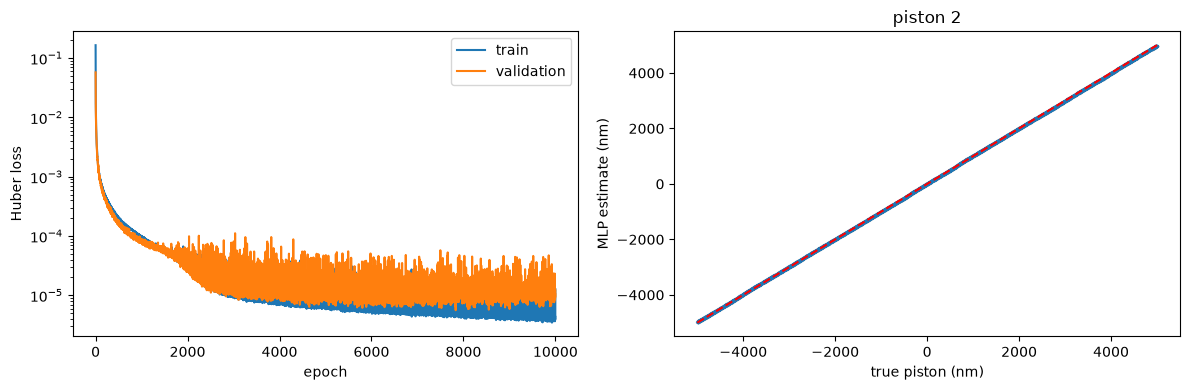

In [3]:
LAYERS = [Xtr.shape[1], 256, 256, 256, 256, M_MODES]
EPOCHS, LR = 10000, 3e-4        # ~5 min on a GPU; the validation loss flattens after ~7000 epochs
MLP_FILE = f"{DATA}/cache_spectral/mlp-{'x'.join(map(str, LAYERS))}-e{EPOCHS}-lr{LR:g}.npz"
if os.path.exists(MLP_FILE) and not cache.retrain:
    params, _, extra = ml.load_mlp(MLP_FILE)
    hist = {"train": extra["train"], "val": extra["val"], "best_epoch": int(extra["best_epoch"])}
else:
    params, hist = ml.train_mlp(LAYERS, Xtr, Ytr, Xva, Yva, epochs=EPOCHS, learning_rate=LR)
    os.makedirs(os.path.dirname(MLP_FILE), exist_ok=True)
    ml.save_mlp(MLP_FILE, params, LAYERS, train=hist["train"], val=hist["val"],
                best_epoch=hist["best_epoch"])
print(f"best epoch {hist['best_epoch']}")
record("MLP", np.asarray(ml.mlp_forward(params, Xva)))

C_mlp = ys.inverse(np.asarray(ml.mlp_forward(params, Xva)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["train"], label="train"); ax[0].plot(hist["val"], label="validation")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("Huber loss"); ax[0].legend()
k = 2
ax[1].scatter(C_va[:, k], C_mlp[:, k], s=2, alpha=0.3)
ax[1].plot([-PISTON_SPAN_NM, PISTON_SPAN_NM], [-PISTON_SPAN_NM, PISTON_SPAN_NM], "r--")
ax[1].set_xlabel("true piston (nm)"); ax[1].set_ylabel("MLP estimate (nm)"); ax[1].set_title(f"piston {k}")
plt.tight_layout(); plt.show()

## Baselines: linear reconstructor and k-nearest neighbours

In [4]:
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

record("linear", cache("linear", lambda: Ridge(1.0).fit(Xtr, Ytr)).predict(Xva))
record("kNN", cache("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(Xtr, Ytr)).predict(Xva))

[cache] fitted and saved linear
linear           mean  2767.4 nm   per mode [2771.4 2769.5 2728.1 2783.5 2784.6]


[cache] fitted and saved kNN


kNN              mean  1245.2 nm   per mode [1262.  1249.7 1194.2 1255.6 1264.3]


## Dense degree-2 polynomial ridge on a wavelength subset

Every degree-2 monomial of the core signals at every `WL_STRIDE`-th
wavelength (raw signals, or their per-wavelength Zernike projection with
`REPR = "zern"`), one ridge per piston. The number of terms grows
quadratically with the inputs and the memory linearly with the rows, so the
fit uses a random `DATA_SHARE` of the training and validation rows and
checks the memory needed first.

In [5]:
REPR, WL_STRIDE, DEGREE = "fiber", 4, 2
DATA_SHARE, MEM_BUDGET_GIB = 0.15, 128.0
wl_fit = np.arange(0, n_wl, WL_STRIDE)

if REPR == "zern":
    B, _ = ml.zernike_basis(ds.core_xy, S["zern_d2"], fill=0.8)
    P = ml.modal_projector(B)
    to_features = lambda S: (S[:, wl_fit] @ P.T).reshape(len(S), -1)
else:
    to_features = lambda S: S[:, wl_fit].reshape(len(S), -1)
fs = ml.Standardizer(eps=1e-9).fit(to_features(S_tr))
fit_rows = ml.subsample_rows(len(S_tr), DATA_SHARE, seed=0)
val_rows = ml.subsample_rows(len(S_va), DATA_SHARE, seed=1)
F_fit, F_val = fs.transform(to_features(S_tr[fit_rows])), fs.transform(to_features(S_va[val_rows]))

n_terms = ml.n_poly_terms(F_fit.shape[1], DEGREE)
need_gib = (1.5 * len(F_fit) + len(F_val)) * n_terms * 8 / 2**30   # RidgeCV needs ~0.5x Z_fit extra
print(f"{len(wl_fit)} wavelengths x {F_fit.shape[1] // len(wl_fit)} {REPR} = {F_fit.shape[1]} inputs "
      f"-> {n_terms:,} terms; {len(F_fit)} fit / {len(F_val)} val rows -> ~{need_gib:.1f} GiB")
assert need_gib <= MEM_BUDGET_GIB, "lower DATA_SHARE (linear) or raise WL_STRIDE (quadratic)"

ridge = cache(f"{REPR}-ridge-d{DEGREE}-w{len(wl_fit)}-n{len(F_fit)}",
              lambda: ml.fit_dense_poly_ridge(F_fit, Ytr[fit_rows], DEGREE, alphas=np.logspace(-2, 6, 17)))
name = f"{REPR}-ridge-d{DEGREE}"
RESULTS[name] = ml.rmse_nm(ys.inverse(ml.predict_dense_poly_ridge(ridge, F_val)), C_va[val_rows])
print(f"{name:16s} mean {RESULTS[name].mean():7.1f} nm   per mode {np.round(RESULTS[name], 1)}"
      f"   (on {len(val_rows)} validation rows)")

11 wavelengths x 19 fiber = 209 inputs -> 22,154 terms; 6000 fit / 1500 val rows -> ~1.7 GiB


[cache] fitted and saved fiber-ridge-d2-w11-n6000
fiber-ridge-d2   mean   397.0 nm   per mode [477.8 457.8 115.7 475.2 458.8]   (on 1500 validation rows)


## Comparison

  no skill (mean)   2893.1 nm   per mode [2888.3 2880.8 2891.4 2908.6 2896.3]
  MLP                  9.5 nm   per mode [ 7.6  8.1 13.   9.8  8.8]
  linear            2767.4 nm   per mode [2771.4 2769.5 2728.1 2783.5 2784.6]
  kNN               1245.2 nm   per mode [1262.  1249.7 1194.2 1255.6 1264.3]
  fiber-ridge-d2     397.0 nm   per mode [477.8 457.8 115.7 475.2 458.8]


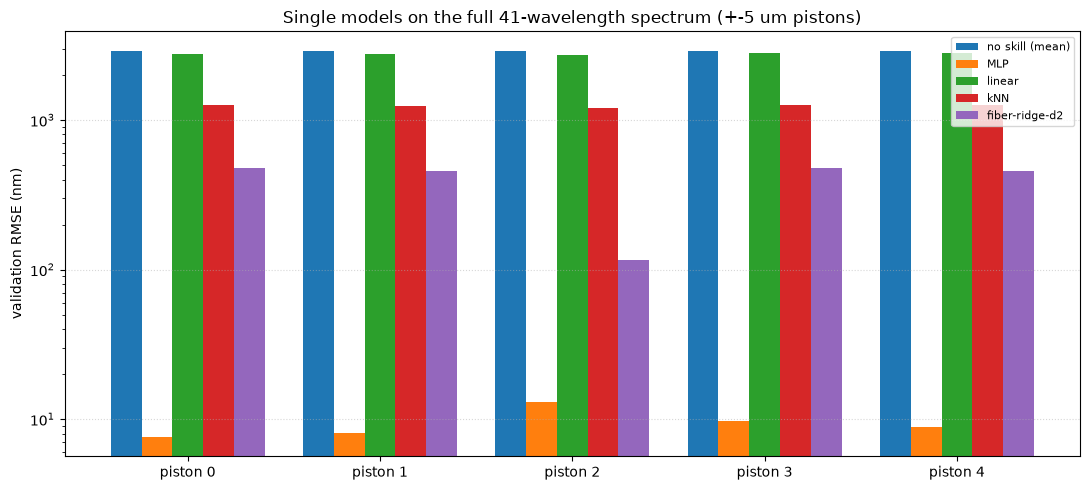

In [6]:
names = list(RESULTS)
for m in names:
    print(f"  {m:16s} {RESULTS[m].mean():7.1f} nm   per mode {np.round(RESULTS[m], 1)}")
x, w = np.arange(M_MODES), 0.8 / len(names)
plt.figure(figsize=(11, 5))
for i, m in enumerate(names):
    plt.bar(x + (i - len(names) / 2 + 0.5) * w, RESULTS[m], w, label=m)
plt.yscale("log"); plt.xticks(x, [f"piston {k}" for k in x]); plt.ylabel("validation RMSE (nm)")
plt.title("Single models on the full 41-wavelength spectrum (+-5 um pistons)")
plt.legend(fontsize=8); plt.grid(True, axis="y", ls=":", alpha=0.5); plt.tight_layout(); plt.show()